In [1]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from pathlib import Path
import geopandas as gpd
import pandas as pd

from urllib.request import urlopen
import json
from IPython.display import Image

import plotly.io as pio
import plotly.express as px       # 편리한 plot 설정 
import plotly.graph_objects as go # 디테일하게 plot을 설정
import plotly.figure_factory as ff
from plotly.subplots import make_subplots

In [2]:
# 한글폰트 설정
plt.rc("font", family="Malgun Gothic")
# 레티나 디스플레이로 폰트를 선명하게 표시
# from IPython.display import set_matplotlib_formats
# set_matplotlib_formats("retina")

%config InlineBackend.figure_format = 'retina'

pd.options.display.float_format = '{:20.3f}'.format

# pd.set_option('display.max_rows', None)
pd.options.display.max_rows = 60

## 1. 서울시 격자 인구 데이터 불러오기

In [3]:
population = pd.read_csv("grid/2024년_인구_다사_100M.csv",
    encoding="cp949",
    header=None,
    names=["year", "GRID_CD", "stat_code", "population"],
    dtype={"GRID_CD": str},
)

population

,year,GRID_CD,stat_code,population
0,2024,다사000395,to_in_001,5
1,2024,다사000395,to_in_007,0
2,2024,다사000395,to_in_008,5
3,2024,다사000398,to_in_001,0
4,2024,다사000398,to_in_007,0
...,...,...,...,...
602419,2024,다사999835,to_in_007,8
602420,2024,다사999835,to_in_008,5
602421,2024,다사999836,to_in_001,0
602422,2024,다사999836,to_in_007,0


In [59]:
# 서울시 행정동 경계

bnd_dong = gpd.read_file(
    "shp/bnd_dong_seoul.shp"
)

print(bnd_dong.shape)
print(bnd_dong.crs)
bnd_dong

(426, 4)
EPSG:5179


,BASE_DATE,ADM_CD,ADM_NM,geometry
0,20250630,11010530,사직동,"POLYGON ((953553.932 1953335.741, 953555.211 1..."
1,20250630,11010540,삼청동,"POLYGON ((953844.082 1955492.177, 953858.644 1..."
2,20250630,11010550,부암동,"POLYGON ((952490.38 1956548.821, 952497.594 19..."
3,20250630,11010560,평창동,"POLYGON ((953683.828 1959209.871, 953665.283 1..."
4,20250630,11010570,무악동,"POLYGON ((952298.144 1953539.606, 952324.838 1..."
...,...,...,...,...
421,20250630,11250730,천호2동,"POLYGON ((966110.271 1950148.101, 966118.161 1..."
422,20250630,11250740,길동,"POLYGON ((968944.218 1949625.263, 968943.832 1..."
423,20250630,11250750,강일동,"POLYGON ((971452.641 1953347.663, 971446.624 1..."
424,20250630,11250760,상일1동,"POLYGON ((971190.564 1949669.365, 971193.744 1..."


In [5]:
# 서울시 100m 격자 불오기
grid = gpd.read_file("grid/seoul_100m_grid_2025.geojson")

# 서울시 격자 좌표계를 서울시 행정동 좌표계와 맞춤
grid = grid.to_crs(bnd_dong.crs)

print(grid .shape)
print(grid.crs)

grid.head()

(61654, 2)
EPSG:5179


,GRID_CD,geometry
0,다사603366,"POLYGON ((960300 1936600, 960400 1936600, 9604..."
1,다사604366,"POLYGON ((960400 1936600, 960500 1936600, 9605..."
2,다사602367,"POLYGON ((960200 1936700, 960300 1936700, 9603..."
3,다사603367,"POLYGON ((960300 1936700, 960400 1936700, 9604..."
4,다사604367,"POLYGON ((960400 1936700, 960500 1936700, 9605..."


In [6]:
# Join total population (to_in_001) to grid by GRID_CD
population_total = population.loc[
    population["stat_code"] == "to_in_001", ["GRID_CD", "population"]
].copy()

grid = grid.merge(
    population_total,
    on="GRID_CD",
    how="left",
    validate="one_to_one",
)

grid.head()


,GRID_CD,geometry,population
0,다사603366,"POLYGON ((960300 1936600, 960400 1936600, 9604...",NaN
1,다사604366,"POLYGON ((960400 1936600, 960500 1936600, 9605...",NaN
2,다사602367,"POLYGON ((960200 1936700, 960300 1936700, 9603...",NaN
3,다사603367,"POLYGON ((960300 1936700, 960400 1936700, 9604...",NaN
4,다사604367,"POLYGON ((960400 1936700, 960500 1936700, 9605...",NaN


In [7]:
# 인구값이 없는 격자가 상당수 존재 (강, 녹지...)
grid.count()

GRID_CD       61654
geometry      61654
population    31340
dtype: int64

In [8]:
# Fill NaN values in the population column with 0
grid["population"] = grid["population"].fillna(0)
grid.count()

GRID_CD       61654
geometry      61654
population    61654
dtype: int64

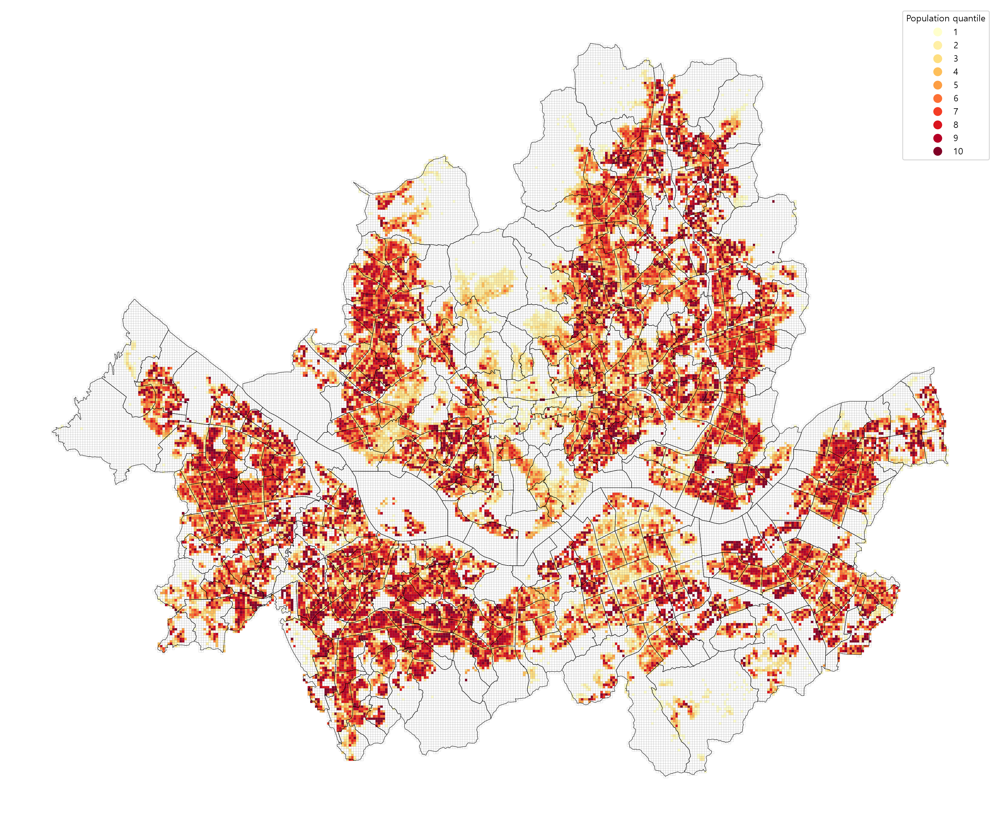

In [9]:
# Map zero population as white and positive population in 10 quantile classes.
# Ties are split by row order to keep exactly 10 equal-sized groups.
positive = grid["population"] > 0
grid_positive = grid.loc[positive].copy()
grid_positive["population_quantile"] = pd.qcut(
    grid_positive["population"].rank(method="first"),
    q=10,
    labels=False,
) + 1


fig, ax = plt.subplots(figsize=(20, 20))

grid.loc[~positive].plot(
    ax=ax,
    facecolor="white",
    edgecolor="gray",
    linewidth=0.1,
)

grid_positive.plot(
    column="population_quantile",
    ax=ax,
    cmap="YlOrRd",
    categorical=True,
    legend=True,
    legend_kwds={"title": "Population quantile"},
    edgecolor="gray",
    linewidth=0.1,
)

bnd_dong.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4,
)


ax.set_aspect("equal")
ax.set_axis_off()
plt.show()


### 지하철 역사 데이터 불러오기
- 서울시 역사 마스터 정보
https://data.seoul.go.kr/dataList/OA-21232/S/1/datasetView.do

In [10]:
# Load Seoul station master data
stations = pd.read_csv(
    "data/서울시 역사마스터 정보.csv",
    encoding="cp949")

print(stations.shape[0])
stations.head()

784


,역사_ID,역사명,호선,위도,경도
0,9010,동탄,수도권 광역급행철도,37.200,127.096
1,9009,구성,수도권 광역급행철도,37.299,127.104
2,9008,성남,수도권 광역급행철도,37.395,127.121
3,9007,수서,수도권 광역급행철도,37.486,127.102
4,9006,삼성,수도권 광역급행철도,37.509,127.063


In [11]:
# Drop duplicate stations based on latitude and longitude
stations = stations.drop_duplicates(
    subset=["위도", "경도"],
    keep="first"
).reset_index(drop=True)

print(stations.shape[0])
stations.head()

781


,역사_ID,역사명,호선,위도,경도
0,9010,동탄,수도권 광역급행철도,37.200,127.096
1,9009,구성,수도권 광역급행철도,37.299,127.104
2,9008,성남,수도권 광역급행철도,37.395,127.121
3,9007,수서,수도권 광역급행철도,37.486,127.102
4,9006,삼성,수도권 광역급행철도,37.509,127.063


In [13]:
# Convert station coordinates to a GeoDataFrame and match the map CRS
stations_gdf = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations["경도"], stations["위도"]),
    crs="EPSG:4326",
).to_crs(grid.crs)

stations_gdf.head()


,역사_ID,역사명,호선,위도,경도,geometry
0,9010,동탄,수도권 광역급행철도,37.200,127.096,POINT (964120.607 1911358.633)
1,9009,구성,수도권 광역급행철도,37.299,127.104,POINT (964894.159 1922315.189)
2,9008,성남,수도권 광역급행철도,37.395,127.121,POINT (966415.922 1932908.37)
3,9007,수서,수도권 광역급행철도,37.486,127.102,POINT (964779.804 1943088.694)
4,9006,삼성,수도권 광역급행철도,37.509,127.063,POINT (961399.221 1945599.967)


In [14]:
stations_gdf.columns

Index(['역사_ID', '역사명', '호선', '위도', '경도', 'geometry'], dtype='str')

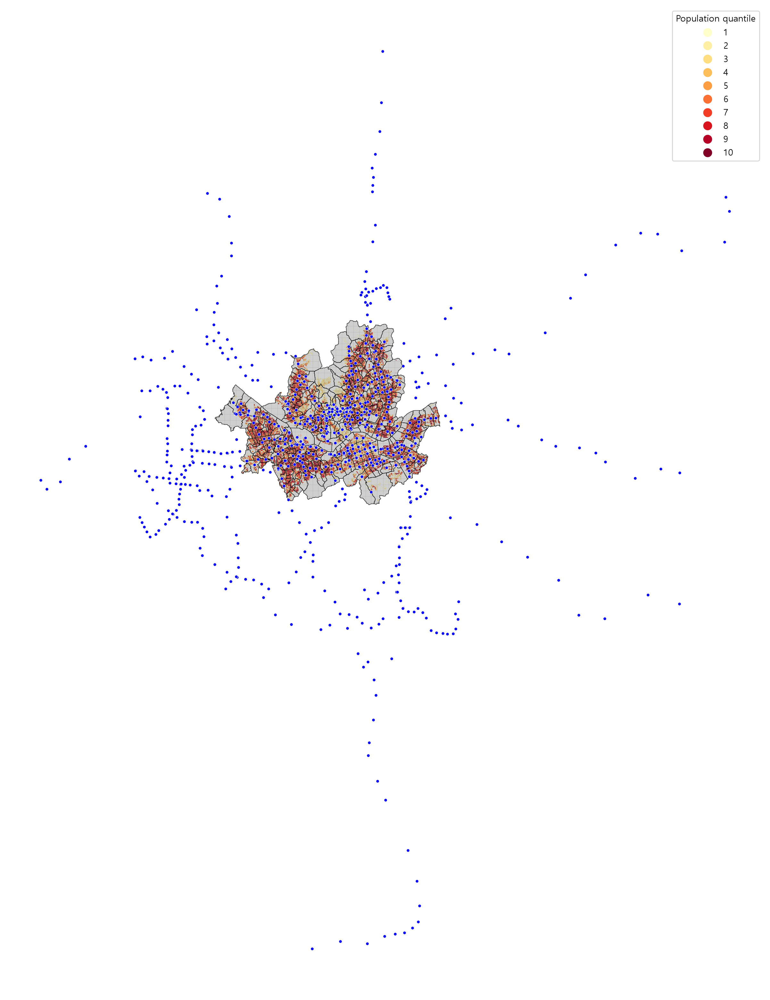

In [15]:
# Map zero population as white and positive population in 10 quantile classes.
# Ties are split by row order to keep exactly 10 equal-sized groups.
positive = grid["population"] > 0
grid_positive = grid.loc[positive].copy()
grid_positive["population_quantile"] = pd.qcut(
    grid_positive["population"].rank(method="first"),
    q=10,
    labels=False,
) + 1


fig, ax = plt.subplots(figsize=(20, 20))

grid.loc[~positive].plot(
    ax=ax,
    facecolor="white",
    edgecolor="gray",
    linewidth=0.1,
)

grid_positive.plot(
    column="population_quantile",
    ax=ax,
    cmap="YlOrRd",
    categorical=True,
    legend=True,
    legend_kwds={"title": "Population quantile"},
    edgecolor="gray",
    linewidth=0.1,
)

bnd_dong.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4,
)

stations_gdf.plot(
    ax=ax,
    color="blue",
    markersize=12,
    edgecolor="white",
    linewidth=0.4,
    label="Stations",
    zorder=5,
)

ax.set_aspect("equal")
ax.set_axis_off()
plt.show()


In [16]:
# 좌표계 일치시키기
stations_in_dong = stations_gdf.to_crs(bnd_dong.crs)

# 서울시 행정동 경계와 겹치는 역사만 추출
stations_in_dong = gpd.sjoin(
    stations_in_dong,
    bnd_dong[["geometry"]],
    how="inner",
    predicate="within",
).drop(columns=["index_right"])

stations_in_dong.head()

,역사_ID,역사명,호선,위도,경도,geometry
3,9007,수서,수도권 광역급행철도,37.486,127.102,POINT (964779.804 1943088.694)
4,9006,삼성,수도권 광역급행철도,37.509,127.063,POINT (961399.221 1945599.967)
5,9005,서울,수도권 광역급행철도,37.556,126.973,POINT (953449.344 1950835.25)
6,9004,연신내,수도권 광역급행철도,37.619,126.921,POINT (948929.576 1957861.655)
10,4929,김포공항,김포골드라인,37.562,126.802,POINT (938343.019 1951673.745)


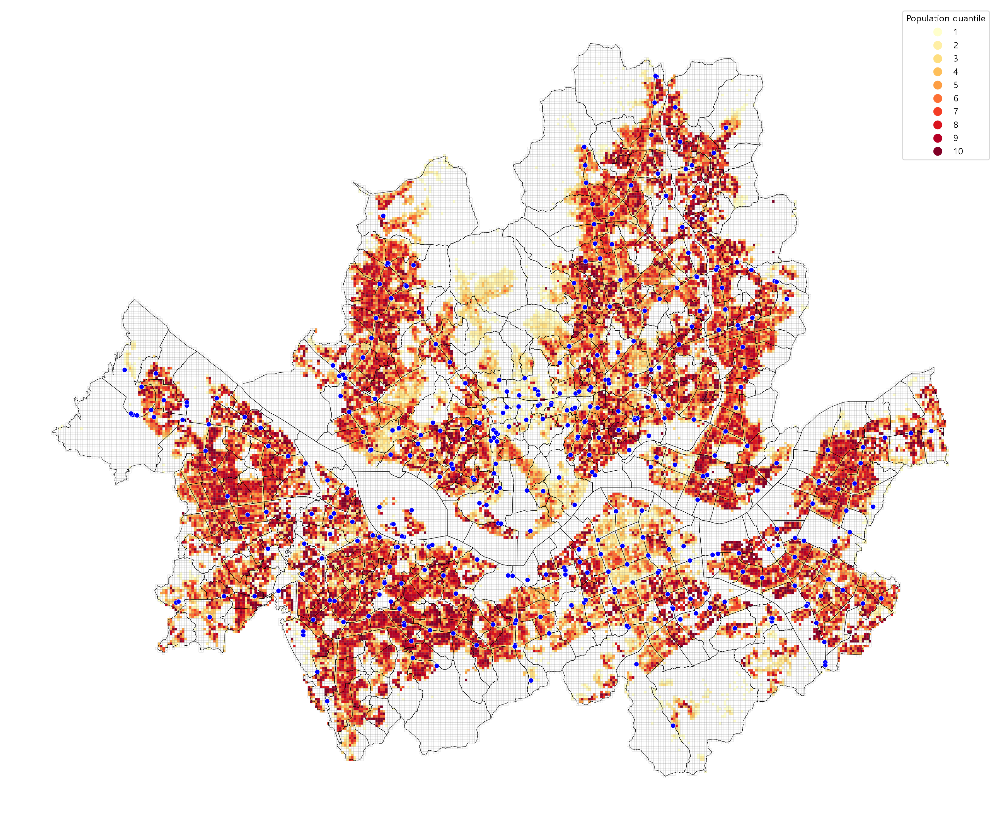

In [17]:
# Map zero population as white and positive population in 10 quantile classes.
# Ties are split by row order to keep exactly 10 equal-sized groups.
positive = grid["population"] > 0
grid_positive = grid.loc[positive].copy()
grid_positive["population_quantile"] = pd.qcut(
    grid_positive["population"].rank(method="first"),
    q=10,
    labels=False,
) + 1


fig, ax = plt.subplots(figsize=(20, 20))

grid.loc[~positive].plot(
    ax=ax,
    facecolor="white",
    edgecolor="gray",
    linewidth=0.1,
)

grid_positive.plot(
    column="population_quantile",
    ax=ax,
    cmap="YlOrRd",
    categorical=True,
    legend=True,
    legend_kwds={"title": "Population quantile"},
    edgecolor="gray",
    linewidth=0.1,
)

bnd_dong.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.4,
)

stations_in_dong.plot(
    ax=ax,
    color="blue",
    markersize=30,
    edgecolor="white",
    linewidth=0.4,
    label="Stations",
    zorder=5,
)

ax.set_aspect("equal")
ax.set_axis_off()
plt.show()


## 행정동별 지하철역 보행 접근성

각 100m 인구 격자의 중심점에서 가장 가까운 역사까지 보행 네트워크 최단거리를 계산합니다. 최단거리를 가정 보행속도로 나누어 보행시간으로 바꾼 뒤, 격자 인구를 가중치로 사용해 행정동별 지표를 만듭니다.

- **인구가중 평균 보행시간**: 격자별 가까운 역사까지 보행시간에 해당 격자 인구를 곱해 합산한 뒤, 접근 가능한 격자의 인구 합으로 나눕니다.
- **10분 이내 도달 인구 비율**: 가장 가까운 역사까지 10분 이내인 격자의 인구를 합산해 행정동 전체 인구로 나눕니다.

보행속도는 예시로 시속 4km를 가정합니다. 실제 보행속도, 경사, 신호 대기, 역사 출입구 위치는 반영하지 않습니다. 역 좌표가 출입구가 아닌 역사 중심점이면 결과는 근사치입니다. 따라서 결과는 실제 문전 간 이동시간이 아니라 **OSM 보행망과 설정한 속도를 이용한 추정치**로 해석해야 합니다.

In [18]:
import osmnx as ox
import networkx as nx
import numpy as np
import geopandas as gpd
import pandas as pd

# 분석 설정
metric_crs = "EPSG:5179"
walk_speed_kmh = 4.0
walk_speed_m_per_min = walk_speed_kmh * 1000 / 60
threshold_min = 10


In [19]:
# 서울시 경계: 행정동 경계를 합쳐 사용
dong_metric = bnd_dong.to_crs(metric_crs)
seoul_boundary_metric = dong_metric.geometry.union_all()

# OSMnx 그래프 다운로드에는 위경도 좌표 사용
seoul_boundary_wgs84 = (
    gpd.GeoSeries([seoul_boundary_metric], crs=metric_crs)
    .to_crs("EPSG:4326")
    .iloc[0]
)

# 서울시 경계 내 보행 네트워크 생성
G = ox.graph_from_polygon(
    seoul_boundary_wgs84,
    network_type="walk",
    simplify=True,
)
G = ox.project_graph(G, to_crs=metric_crs)
G_walk = ox.convert.to_undirected(G)





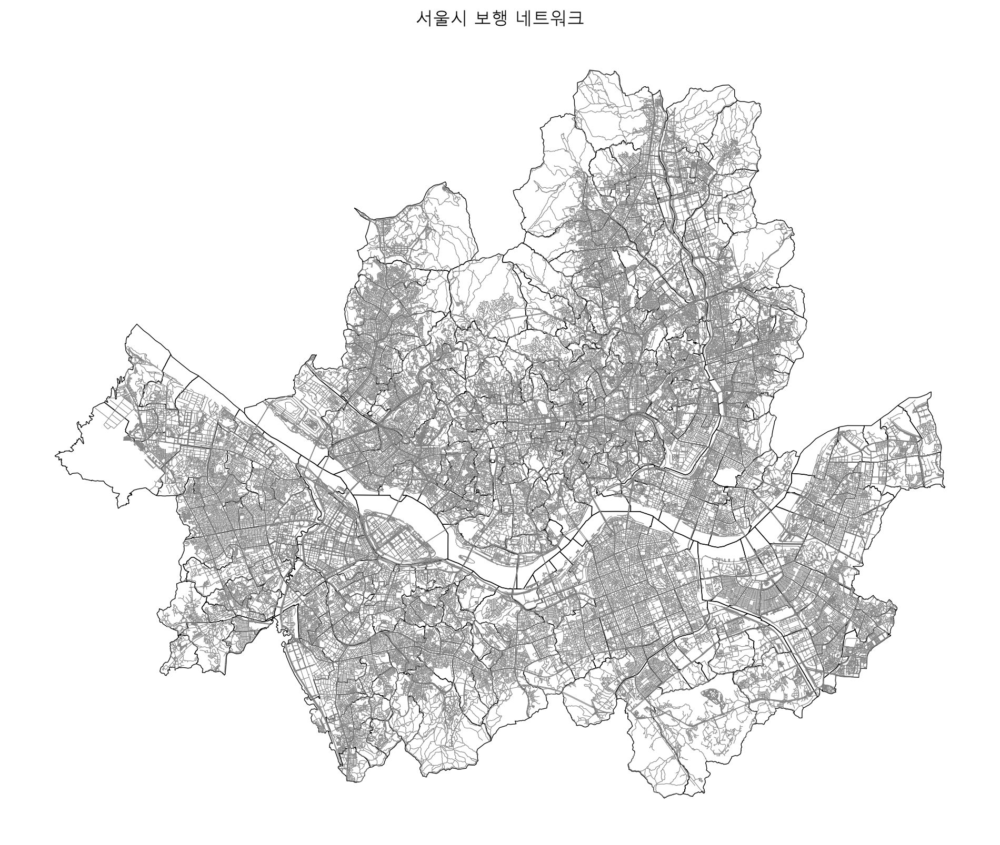

In [20]:
nodes, edges = ox.graph_to_gdfs(G_walk)

fig, ax = plt.subplots(figsize=(12, 12))

dong_metric.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.5,
)

edges.plot(
    ax=ax,
    color="gray",
    linewidth=0.4,
)

ax.set_title("서울시 보행 네트워크")
ax.set_axis_off()
plt.show()

In [21]:
# 서울 행정동에 포함된 역 레이어 사용
stations_metric = (
    stations_in_dong
    .to_crs(metric_crs)
    .drop_duplicates(subset=["geometry"])
    .copy()
)

if stations_metric.empty:
    raise ValueError("연구지역 버퍼 안에 역이 없습니다. 역 좌표계와 위치를 확인하세요.")

station_nodes = ox.distance.nearest_nodes(
    G_walk,
    X=stations_metric.geometry.x.to_numpy(),
    Y=stations_metric.geometry.y.to_numpy(),
)

# 역 네트워크 노드들에서 모든 보행망 노드까지의 최단거리 계산
distance_to_station_m = nx.multi_source_dijkstra_path_length(
    G_walk,
    sources=set(np.atleast_1d(station_nodes)),
    weight="length",
)

# 100m 격자 중심점을 보행망에 연결
grid_points = grid[["GRID_CD", "population", "geometry"]].copy()
grid_points["geometry"] = grid_points.geometry.centroid
grid_points = gpd.GeoDataFrame(
    grid_points,
    geometry="geometry",
    crs=grid.crs,
).to_crs(metric_crs)

# 100m 격자 중심점에 가장 가까운 보행망 노드 찾기
grid_nodes = ox.distance.nearest_nodes(
    G_walk,
    X=grid_points.geometry.x.to_numpy(),
    Y=grid_points.geometry.y.to_numpy(),
)


# 역 네트워크 노드들에서 모든 보행망 노드까지의 최단거리 계산
distance_to_station_m = nx.multi_source_dijkstra_path_length(
    G_walk,
    sources=set(np.atleast_1d(station_nodes)),
    weight="length",
)

# 100m 격자 중심점을 보행망에 연결
grid_points = grid[["GRID_CD", "population", "geometry"]].copy()
grid_points["geometry"] = grid_points.geometry.centroid
grid_points = gpd.GeoDataFrame(
    grid_points,
    geometry="geometry",
    crs=grid.crs,
).to_crs(metric_crs)

grid_nodes = ox.distance.nearest_nodes(
    G_walk,
    X=grid_points.geometry.x.to_numpy(),
    Y=grid_points.geometry.y.to_numpy(),
)

# 최단거리와 추정 보행시간 계산
grid_points["walk_dist_m"] = [
    distance_to_station_m.get(node, np.nan)
    for node in grid_nodes
]
grid_points["walk_min"] = (
    grid_points["walk_dist_m"] / walk_speed_m_per_min
)



In [22]:
grid_points.sample(10)

,GRID_CD,population,geometry,walk_dist_m,walk_min
55179,다사509600,0.000,POINT (950950 1960050),2979.005,44.685
14516,다사670445,168.000,POINT (967050 1944550),338.403,5.076
28668,다사533494,23.000,POINT (953350 1949450),306.498,4.597
2563,다사571398,272.000,POINT (957150 1939850),3192.704,47.891
47076,다사514556,312.000,POINT (951450 1955650),1616.197,24.243
14127,다사589444,232.000,POINT (958950 1944450),291.825,4.377
16316,다사675451,33.000,POINT (967550 1945150),597.190,8.958
21837,다사527471,71.000,POINT (952750 1947150),1039.361,15.590
5520,다사541413,0.000,POINT (954150 1941350),781.774,11.727
41159,다사407531,0.000,POINT (940750 1953150),1269.239,19.039


In [23]:
# 격자 중심점을 행정동에 배정
grid_points = gpd.sjoin(
    grid_points,
    dong_metric[["ADM_CD", "geometry"]],
    how="inner",
    predicate="within",
).drop(columns=["index_right"])

# 인구가중 지표 계산
grid_points["population"] = pd.to_numeric(
    grid_points["population"],
    errors="coerce",
).fillna(0)

grid_points["reachable_population"] = np.where(
    grid_points["walk_min"].notna(),
    grid_points["population"],
    0,
)

grid_points["population_x_walk_min"] = (
    grid_points["reachable_population"]
    * grid_points["walk_min"].fillna(0)
)

grid_points["population_within_10min"] = np.where(
    grid_points["walk_min"] <= threshold_min,
    grid_points["population"],
    0,
)



In [24]:
grid_points.sample(10)


,GRID_CD,population,geometry,walk_dist_m,walk_min,ADM_CD,reachable_population,population_x_walk_min,population_within_10min
43586,다사549540,0.000,POINT (954950 1954050),1192.292,17.884,11010610,0.000,0.000,0.000
15710,다사654449,55.000,POINT (965450 1944950),408.127,6.122,11240610,55.000,336.705,55.000
58659,다사629627,0.000,POINT (962950 1962750),666.316,9.995,11110760,0.000,0.000,0.000
9248,다사425428,0.000,POINT (942550 1942850),1298.033,19.471,11170650,0.000,0.000,0.000
5998,다사569415,0.000,POINT (956950 1941550),1628.775,24.432,11220660,0.000,0.000,0.000
17710,다사652456,348.000,POINT (965250 1945650),477.929,7.169,11240610,348.000,2494.789,348.000
39735,다사468526,0.000,POINT (946850 1952650),1164.463,17.467,11140730,0.000,0.000,0.000
45812,다사507550,312.000,POINT (950750 1955050),753.068,11.296,11130660,312.000,3524.359,0.000
3071,다사568401,0.000,POINT (956850 1940150),3615.119,54.227,11220660,0.000,0.000,0.000
56510,다사621608,0.000,POINT (962150 1960850),1169.852,17.548,11110610,0.000,0.000,0.000


In [25]:
dong_accessibility = (
    grid_points.groupby("ADM_CD", as_index=False)
    .agg(
        total_population=("population", "sum"),
        reachable_population=("reachable_population", "sum"),
        population_x_walk_min=("population_x_walk_min", "sum"),
        population_within_10min=("population_within_10min", "sum"),
    )
)

# 인구가중 평균 보행시간
dong_accessibility["population_weighted_walk_min"] = (
    dong_accessibility["population_x_walk_min"]
    / dong_accessibility["reachable_population"].replace(0, np.nan)
)

# 10분 이내 도달 가능한 인구 비율
dong_accessibility["population_within_10min_pct"] = (
    dong_accessibility["population_within_10min"]
    / dong_accessibility["total_population"].replace(0, np.nan)
    * 100
)

# 행정동 경계와 결합해 지도에 사용할 수 있는 결과 생성
dong_accessibility = dong_metric.merge(
    dong_accessibility,
    on="ADM_CD",
    how="left",
)

dong_accessibility[
    [
        "ADM_CD",
        "total_population",
        "population_weighted_walk_min",
        "population_within_10min_pct",
    ]
].head()

,ADM_CD,total_population,population_weighted_walk_min,population_within_10min_pct
0,11010530,8472.000,9.191,72.273
1,11010540,1941.000,14.506,19.732
2,11010550,9203.000,43.758,0.000
3,11010560,16357.000,53.514,0.000
4,11010570,7646.000,5.193,94.886


In [26]:
# 접근성 표의 geometry를 제외하고 경계 속성에 결합
dong_accessibility_map = bnd_dong.merge(
    dong_accessibility.drop(columns="geometry", errors="ignore"),
    on="ADM_CD",
    how="left",
)

dong_accessibility_map.head()

,BASE_DATE_x,ADM_CD,ADM_NM_x,geometry,BASE_DATE_y,ADM_NM_y,total_population,reachable_population,population_x_walk_min,population_within_10min,population_weighted_walk_min,population_within_10min_pct
0,20250630,11010530,사직동,"POLYGON ((953553.932 1953335.741, 953555.211 1...",20250630,사직동,8472.000,8472.000,77869.076,6123.000,9.191,72.273
1,20250630,11010540,삼청동,"POLYGON ((953844.082 1955492.177, 953858.644 1...",20250630,삼청동,1941.000,1941.000,28156.086,383.000,14.506,19.732
2,20250630,11010550,부암동,"POLYGON ((952490.38 1956548.821, 952497.594 19...",20250630,부암동,9203.000,9203.000,402701.405,0.000,43.758,0.000
3,20250630,11010560,평창동,"POLYGON ((953683.828 1959209.871, 953665.283 1...",20250630,평창동,16357.000,16357.000,875320.596,0.000,53.514,0.000
4,20250630,11010570,무악동,"POLYGON ((952298.144 1953539.606, 952324.838 1...",20250630,무악동,7646.000,7646.000,39702.767,7255.000,5.193,94.886


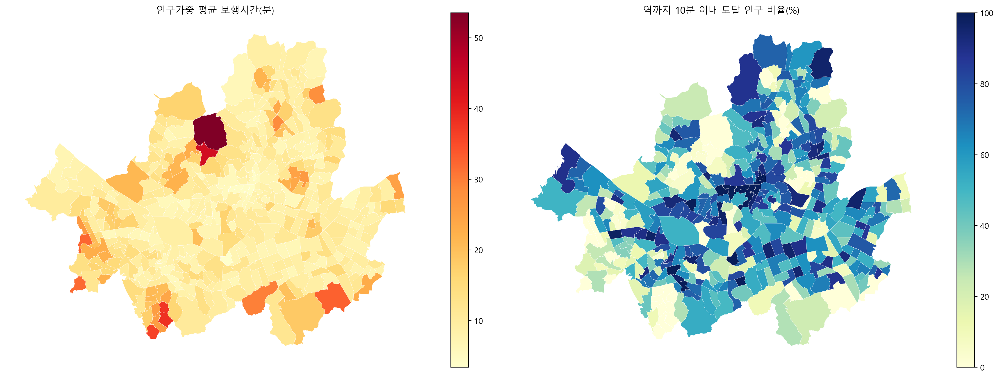

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

dong_accessibility_map.plot(
    column="population_weighted_walk_min",
    ax=axes[0],
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"shrink": 0.7},
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "자료 없음"},
)
axes[0].set_title("인구가중 평균 보행시간(분)")
axes[0].set_axis_off()

dong_accessibility_map.plot(
    column="population_within_10min_pct",
    ax=axes[1],
    cmap="YlGnBu",
    legend=True,
    legend_kwds={"shrink": 0.7},
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "자료 없음"},
)
axes[1].set_title("역까지 10분 이내 도달 인구 비율(%)")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

### 중력형 역사 접근성 지표

중력형 접근성 지표는 각 격자에서 여러 역사까지의 이동시간을 고려해 접근성을 계산합니다. 가까운 역은 크게, 먼 역은 작게 반영하며, 역별 운행 빈도나 노선 수 같은 서비스 수준을 가중치로 넣을 수도 있습니다.

$$
A_i = \sum_j S_j e^{-\beta t_{ij}}
$$

또는 

$$
A_i = \sum_j S_j \exp(-\beta t_{ij})
$$

- $A_i$: 격자 $i$의 역사 접근성 점수
- $t_{ij}$: 격자 $i$에서 역사 $j$까지의 보행시간
- $S_j$: 역사 $j$의 서비스 가중치
- $\beta$: 보행시간에 따른 접근성 감소 정도를 정하는 계수

“접근성이 좋은 곳에 얼마나 많은 사람이 사는가”
$$
A_d =
\sum_{i \in d} P_i A_i
$$

"해당 지역 주민이 평균적으로 누리는 접근성"
$$
A_d =
\frac{\sum_{i \in d} P_i A_i}
     {\sum_{i \in d} P_i}
$$

여기서 $P_i$는 격자 $i$의 인구입니다. 따라서 인구가 많은 격자의 접근성이 행정동 점수에 더 크게 반영됩니다.

이 지표는 일정 거리 안의 역 개수를 세는 방식과 달리, 역까지의 시간이 멀어질수록 기여도가 점진적으로 감소합니다. 다만 \(\beta\), 이동시간 산정 방식, 역별 서비스 가중치에 따라 점수가 달라지므로, 설정값과 해석 기준을 함께 기록해야 합니다.

##### 1. 최단역까지의 기여도만 고려 (직선거리)

In [42]:
# 격자 중심점 생성
grid_centers = grid.to_crs("EPSG:5179").copy()
grid_centers["geometry"] = grid_centers.geometry.centroid

# 역사 위치의 좌표계 통일 및 중복 제거
station_points = (
    stations_in_dong.to_crs("EPSG:5179")[["geometry"]]
    .drop_duplicates()
)

# 각 격자 중심에서 최근접 역사까지 직선거리 계산
grid_centers = gpd.sjoin_nearest(
    grid_centers,
    station_points,
    how="left",
    distance_col="nearest_station_straight_m",
).drop(columns="index_right")

# 같은 거리에 역이 여러 개 있는 경우 격자당 한 행만 유지
grid_centers = grid_centers.drop_duplicates(subset="GRID_CD")

grid_centers[
    ["GRID_CD", "nearest_station_straight_m"]
].sample(10)

,GRID_CD,nearest_station_straight_m
56485,다사596608,745.196
9340,다사532428,98.710
5043,다사511411,239.988
28532,다사397494,1766.823
47775,다사605559,621.729
43106,다사559538,98.122
21704,다사680470,281.276
54394,다사551595,2279.274
20240,다사636465,684.212
6400,다사515417,801.892


In [53]:
# 보행속도와 시간 감쇠계수
walk_speed_m_per_min = 4.0 * 1000 / 60
beta = np.log(2) / 10
max_walk_min = 30

grid_centers["straight_walk_min"] = (
    grid_centers["nearest_station_straight_m"] / walk_speed_m_per_min
)

grid_centers["gravity_nearest_straight"] = np.where(
    grid_centers["straight_walk_min"] <= max_walk_min,
    np.exp(-beta * grid_centers["straight_walk_min"]),
    0.0,
)

grid_centers[
    [
        "GRID_CD",
        "population",
        "nearest_station_straight_m",
        "straight_walk_min",
        "gravity_nearest_straight",
    ]
].head()

,GRID_CD,population,nearest_station_straight_m,straight_walk_min,gravity_nearest_straight
0,다사603366,0.000,2140.831,32.112,0.000
1,다사604366,0.000,2126.895,31.903,0.000
2,다사602367,0.000,2061.587,30.924,0.000
3,다사603367,0.000,2042.221,30.633,0.000
4,다사604367,0.000,2027.607,30.414,0.000


In [54]:
grid_centers.sample(10)

,GRID_CD,geometry,population,nearest_station_straight_m,straight_walk_min,gravity_nearest_straight
15352,다사597448,POINT (959750 1944850),558.000,402.918,6.044,0.658
50110,다사607571,POINT (960750 1957150),0.000,286.107,4.292,0.743
13377,다사455442,POINT (945550 1944250),579.000,812.174,12.183,0.430
29556,다사403497,POINT (940350 1949750),0.000,1097.956,16.469,0.319
8067,다사617423,POINT (961750 1942350),0.000,1062.364,15.935,0.331
37414,다사397519,POINT (939750 1951950),380.000,305.395,4.581,0.728
6989,다사604419,POINT (960450 1941950),0.000,1327.058,19.906,0.252
45982,다사395551,POINT (939550 1955150),0.000,1824.726,27.371,0.150
21482,다사458470,POINT (945850 1947050),349.000,498.555,7.478,0.595
23087,다사629475,POINT (962950 1947550),0.000,1260.075,18.901,0.270


In [48]:
np.exp(-beta * 9.337)

np.float64(0.5235139913436231)

In [49]:
# 10분 거리의 기여도는 0.5
np.exp(-beta * 10)

np.float64(0.5)

In [50]:
# 30분 거리의 기여도는 0.125
np.exp(-beta * 30)

np.float64(0.12500000000000003)

In [55]:
# 인구가중 기여도 산출
grid_centers["population_x_gravity"] = (
    grid_centers["population"]
    * grid_centers["gravity_nearest_straight"]
)

grid_centers[
    ["GRID_CD", "population", "gravity_nearest_straight",
     "population_x_gravity"]
].sample(20)

,GRID_CD,population,gravity_nearest_straight,population_x_gravity
59950,다사640641,0.000,0.248,0.000
7373,다사460421,87.000,0.466,40.558
20652,다사479467,248.000,0.691,171.246
42203,다사649534,0.000,0.261,0.000
5598,다사619413,0.000,0.132,0.000
7904,다사454423,0.000,0.832,0.000
23269,다사525476,38.000,0.693,26.352
38023,다사692520,0.000,0.238,0.000
43995,다사474542,0.000,0.597,0.000
61230,다사579657,0.000,0.000,0.000


In [57]:
# 격자 중심점을 행정동에 배정
grid_centers = gpd.sjoin(
    grid_centers,
    dong_metric[["ADM_CD", "geometry"]],
    how="left",
    predicate="within",
).drop(columns=["index_right"], errors="ignore")

# 행정동별 합산
dong_gravity_straight = (
    grid_centers.groupby("ADM_CD", as_index=False)
    .agg(
        total_population=("population", "sum"),
        population_x_gravity=("population_x_gravity", "sum"),
    )
)

# 행정동별 인구가중 기여도 산출
dong_gravity_straight["population_weighted_gravity_straight"] = (
    dong_gravity_straight["population_x_gravity"]
    / dong_gravity_straight["total_population"].replace(0, np.nan)
)

dong_gravity_straight.sample(20)

,ADM_CD,total_population,population_x_gravity,population_weighted_gravity_straight
40,11030650,6943.000,5035.589,0.725
126,11080820,21484.000,14225.753,0.662
152,11100610,12763.000,3699.523,0.290
323,11210610,15692.000,10507.998,0.670
110,11080580,14207.000,9361.974,0.659
7,11010610,9106.000,6793.632,0.746
186,11120670,16273.000,11403.349,0.701
308,11200560,28412.000,13962.951,0.491
270,11170690,22154.000,11899.458,0.537
125,11080810,14753.000,7508.706,0.509


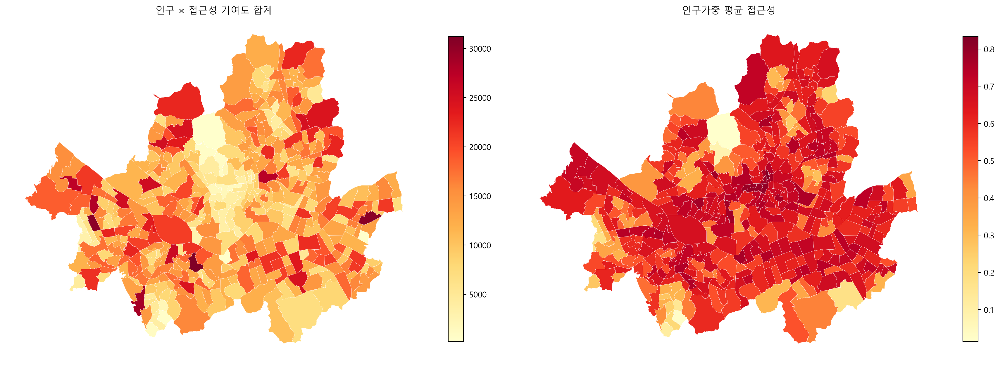

In [58]:
import matplotlib.pyplot as plt

# 행정동 경계에 두 지표 결합
plot_map = bnd_dong.merge(
    dong_gravity_straight[
        ["ADM_CD", "population_x_gravity",
         "population_weighted_gravity_straight"]
    ],
    on="ADM_CD",
    how="left",
)

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

settings = [
    ("population_x_gravity", "인구 × 접근성 기여도 합계"),
    ("population_weighted_gravity_straight", "인구가중 평균 접근성"),
]

for ax, (column, title) in zip(axes, settings):
    plot_map.plot(
        column=column,
        ax=ax,
        cmap="YlOrRd",
        legend=True,
        legend_kwds={"shrink": 0.6},
        edgecolor="white",
        linewidth=0.2,
        missing_kwds={"color": "lightgrey"},
    )
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

**** 1-1. 네트워크 거리 사용 

In [28]:
import numpy as np
import pandas as pd
import networkx as nx
import osmnx as ox
from pyproj import CRS

# Shared settings for both gravity measures: minutes, metres, and a 30-min limit.
metric_crs = "EPSG:5179"
walk_speed_kmh = 4.0
walk_speed_m_per_min = walk_speed_kmh * 1000 / 60
beta = np.log(2) / 10
max_walk_min = 30.0
max_walk_dist_m = max_walk_min * walk_speed_m_per_min

if CRS(G_walk.graph["crs"]) != CRS(metric_crs):
    raise ValueError("G_walk must use EPSG:5179, matching the point coordinates.")
if G_walk.is_directed():
    raise ValueError("Use the undirected walking graph for both measures.")

grid_points = grid_points.copy().to_crs(metric_crs).reset_index(drop=True)
grid_points = grid_points.set_geometry(grid_points.geometry.centroid)
grid_points["population"] = pd.to_numeric(
    grid_points["population"], 
    errors="coerce"  # 숫자로 변환할 수 없는 값을 NaN(결측값)으로 바꾸는 옵션
).fillna(0)

stations_metric = (
    stations_in_dong.to_crs(metric_crs)
    .loc[lambda df: df.geometry.notna() & ~df.geometry.is_empty]
    .drop_duplicates(subset=["geometry"])
    .copy()
)
if stations_metric.empty:
    raise ValueError("stations_in_dong contains no valid station points.")
# One contribution per distinct station location.
# Keep weights at 1 for the comparison with the nearest-station proxy.
stations_metric["service_weight"] = 1.0

grid_nodes = ox.distance.nearest_nodes(
    G_walk, X=grid_points.geometry.x.to_numpy(),
    Y=grid_points.geometry.y.to_numpy(),
)
station_nodes = ox.distance.nearest_nodes(
    G_walk, X=stations_metric.geometry.x.to_numpy(),
    Y=stations_metric.geometry.y.to_numpy(),
)
network_nodes = ox.graph_to_gdfs(G_walk, nodes=True, edges=False)
grid_node_xy = network_nodes.loc[grid_nodes, ["x", "y"]].to_numpy()
station_node_xy = network_nodes.loc[station_nodes, ["x", "y"]].to_numpy()
grid_snap_m = np.hypot(
    grid_points.geometry.x.to_numpy() - grid_node_xy[:, 0],
    grid_points.geometry.y.to_numpy() - grid_node_xy[:, 1],
)
station_snap_m = np.hypot(
    stations_metric.geometry.x.to_numpy() - station_node_xy[:, 0],
    stations_metric.geometry.y.to_numpy() - station_node_xy[:, 1],
)

# A temporary source connects to each station node with the station's
# connection distance. This includes the station offset in the nearest path.
G_nearest = G_walk.copy()
virtual_source = ("gravity_station_source",)
for station_node, offset_m in zip(station_nodes, station_snap_m):
    G_nearest.add_edge(virtual_source, station_node, length=float(offset_m))
nearest_distances_m = nx.single_source_dijkstra_path_length(
    G_nearest, source=virtual_source,
    cutoff=max_walk_dist_m, weight="length",
)
del G_nearest

nearest_total_m = np.array([
    nearest_distances_m.get(node, np.inf) for node in grid_nodes
]) + grid_snap_m
nearest_minutes = nearest_total_m / walk_speed_m_per_min
within_limit = nearest_minutes <= max_walk_min
# Keep the earlier walk_min column intact for the earlier walking-time analysis.
grid_points["nearest_walk_min_30min"] = np.where(
    within_limit, nearest_minutes, np.nan
)
grid_points["gravity_nearest_proxy"] = np.where(
    within_limit, np.exp(-beta * nearest_minutes), 0.0
)
# Compatibility alias: both names now contain the same 30-min result.
grid_points["gravity_nearest_proxy_30min"] = grid_points["gravity_nearest_proxy"]
grid_points["population_x_nearest"] = (
    grid_points["population"] * grid_points["gravity_nearest_proxy"]
)

grid_points[[
    "GRID_CD", "population", "nearest_walk_min_30min",
    "gravity_nearest_proxy", "population_x_nearest",
]].sample(10)


,GRID_CD,population,nearest_walk_min_30min,gravity_nearest_proxy,population_x_nearest
49686,다사632573,216.000,13.308,0.398,85.870
54460,다사551601,0.000,NaN,0.000,0.000
40175,다사707529,0.000,NaN,0.000,0.000
3447,다사611404,0.000,NaN,0.000,0.000
38218,다사505523,0.000,22.175,0.215,0.000
51903,다사488586,65.000,13.278,0.398,25.894
22869,다사592476,34.000,3.780,0.770,26.164
479,다사479381,0.000,NaN,0.000,0.000
17431,다사529457,0.000,11.167,0.461,0.000
12950,다사427442,544.000,16.171,0.326,177.344


In [30]:
# Population-weighted nearest-station score, including zero scores.
dong_gravity = (
    grid_points.groupby("ADM_CD", as_index=False)
    .agg(
        total_population=("population", "sum"),
        population_x_nearest=("population_x_nearest", "sum"),
    )
)
dong_gravity["gravity_nearest_proxy"] = (
    dong_gravity["population_x_nearest"]
    / dong_gravity["total_population"].replace(0, np.nan)
)
dong_gravity[["ADM_CD", "total_population", "gravity_nearest_proxy"]].head(10)


,ADM_CD,total_population,gravity_nearest_proxy
0,11010530,8472.000,0.516
1,11010540,1941.000,0.385
2,11010550,9203.000,0.000
3,11010560,16357.000,0.000
4,11010570,7646.000,0.675
5,11010580,8826.000,0.522
6,11010600,3654.000,0.459
7,11010610,9106.000,0.658
8,11010630,5556.000,0.567
9,11010640,8060.000,0.517


In [31]:
dong_gravity_map = bnd_dong.merge(
    dong_gravity[["ADM_CD", "gravity_nearest_proxy"]],
    on="ADM_CD",
    how="left",
)

In [32]:
dong_gravity_map

,BASE_DATE,ADM_CD,ADM_NM,geometry,gravity_nearest_proxy
0,20250630,11010530,사직동,"POLYGON ((953553.932 1953335.741, 953555.211 1...",0.516
1,20250630,11010540,삼청동,"POLYGON ((953844.082 1955492.177, 953858.644 1...",0.385
2,20250630,11010550,부암동,"POLYGON ((952490.38 1956548.821, 952497.594 19...",0.000
3,20250630,11010560,평창동,"POLYGON ((953683.828 1959209.871, 953665.283 1...",0.000
4,20250630,11010570,무악동,"POLYGON ((952298.144 1953539.606, 952324.838 1...",0.675
...,...,...,...,...,...
421,20250630,11250730,천호2동,"POLYGON ((966110.271 1950148.101, 966118.161 1...",0.543
422,20250630,11250740,길동,"POLYGON ((968944.218 1949625.263, 968943.832 1...",0.556
423,20250630,11250750,강일동,"POLYGON ((971452.641 1953347.663, 971446.624 1...",0.187
424,20250630,11250760,상일1동,"POLYGON ((971190.564 1949669.365, 971193.744 1...",0.341


#### 2. 모든역까지의 기여도를 합산

In [33]:
# Sum all station contributions using exactly the settings, station list,
# snapped nodes and connection distances prepared in the nearest-station cell.
node_to_grid_rows = {}
for row_idx, node in enumerate(grid_nodes):
    node_to_grid_rows.setdefault(node, []).append(row_idx)
node_to_grid_rows = {
    node: np.asarray(rows, dtype=int)
    for node, rows in node_to_grid_rows.items()
}
gravity_score = np.zeros(len(grid_points), dtype=float)

for station_node, station_offset_m, service_weight in zip(
    station_nodes, station_snap_m, stations_metric["service_weight"],
):
    distances_m = nx.single_source_dijkstra_path_length(
        G_walk, source=station_node,
        cutoff=max_walk_dist_m, weight="length",
    )
    for network_node, network_distance_m in distances_m.items():
        rows = node_to_grid_rows.get(network_node)
        if rows is None:
            continue
        total_distance_m = (
            network_distance_m + station_offset_m + grid_snap_m[rows]
        )
        walk_minutes = total_distance_m / walk_speed_m_per_min
        within_limit = walk_minutes <= max_walk_min
        gravity_score[rows[within_limit]] += (
            service_weight * np.exp(-beta * walk_minutes[within_limit])
        )

grid_points["gravity_accessibility"] = gravity_score
# With S_j=1, the sum must include at least the nearest station's contribution.
assert np.all(
    gravity_score + 1e-10 >= grid_points["gravity_nearest_proxy"].to_numpy()
), "All-station and nearest-station calculations are inconsistent."
grid_points[["GRID_CD", "population", "gravity_accessibility"]].head()


,GRID_CD,population,gravity_accessibility
0,다사603367,0.000,0.000
1,다사604367,0.000,0.000
2,다사605367,0.000,0.000
3,다사615367,0.000,0.000
4,다사602368,0.000,0.000


In [34]:
# Use a separate numerator so rerunning cells cannot mix the two measures.
grid_points["population_x_all_gravity"] = (
    grid_points["population"] * grid_points["gravity_accessibility"]
)
dong_gravity2 = (
    grid_points.groupby("ADM_CD", as_index=False)
    .agg(
        total_population=("population", "sum"),
        population_x_all_gravity=("population_x_all_gravity", "sum"),
    )
)
dong_gravity2["population_weighted_gravity"] = (
    dong_gravity2["population_x_all_gravity"]
    / dong_gravity2["total_population"].replace(0, np.nan)
)
dong_gravity2.head()


,ADM_CD,total_population,population_x_all_gravity,population_weighted_gravity
0,11010530,8472.000,20252.858,2.391
1,11010540,1941.000,2767.121,1.426
2,11010550,9203.000,0.000,0.000
3,11010560,16357.000,0.000,0.000
4,11010570,7646.000,10033.946,1.312


In [35]:
# Rebuild from the boundary layer: safe to rerun without _x/_y columns.
dong_gravity_map = (
    bnd_dong.merge(
        dong_gravity[["ADM_CD", "gravity_nearest_proxy"]],
        on="ADM_CD", how="left", validate="one_to_one",
    ).merge(
        dong_gravity2[["ADM_CD", "population_weighted_gravity"]],
        on="ADM_CD", how="left", validate="one_to_one",
    )
)


In [36]:
dong_gravity_map.head()

,BASE_DATE,ADM_CD,ADM_NM,geometry,gravity_nearest_proxy,population_weighted_gravity
0,20250630,11010530,사직동,"POLYGON ((953553.932 1953335.741, 953555.211 1...",0.516,2.391
1,20250630,11010540,삼청동,"POLYGON ((953844.082 1955492.177, 953858.644 1...",0.385,1.426
2,20250630,11010550,부암동,"POLYGON ((952490.38 1956548.821, 952497.594 19...",0.000,0.000
3,20250630,11010560,평창동,"POLYGON ((953683.828 1959209.871, 953665.283 1...",0.000,0.000
4,20250630,11010570,무악동,"POLYGON ((952298.144 1953539.606, 952324.838 1...",0.675,1.312


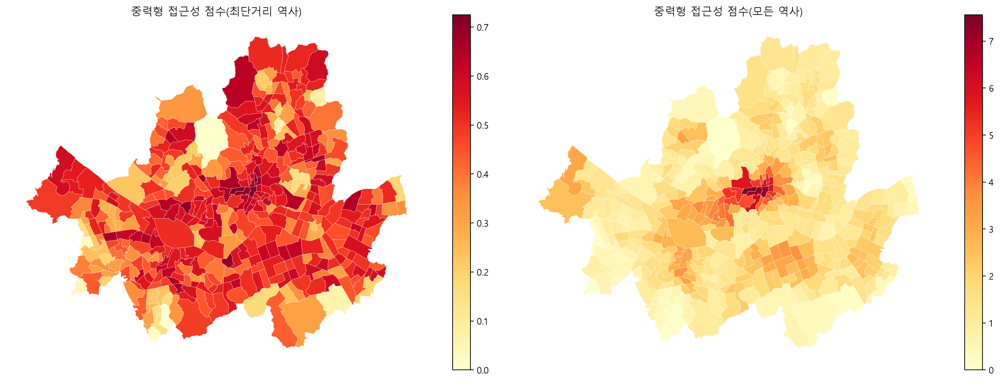

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

plot_settings = [
    ("gravity_nearest_proxy", "중력형 접근성 점수(최단거리 역사)"),
    ("population_weighted_gravity", "중력형 접근성 점수(모든 역사)"),
]

for ax, (column, title) in zip(axes, plot_settings):
    dong_gravity_map.plot(
        column=column,
        ax=ax,
        cmap="YlOrRd",
        legend=True,
        legend_kwds={"shrink": 0.7},
        edgecolor="white",
        linewidth=0.2,
        missing_kwds={"color": "lightgrey", "label": "자료 없음"},
    )
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [38]:
dong_gravity_map[
    ["gravity_nearest_proxy", "population_weighted_gravity"]
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

,gravity_nearest_proxy,population_weighted_gravity
count,426.000,426.000
mean,0.466,1.776
std,0.139,1.224
min,0.000,0.000
25%,0.396,1.022
50%,0.502,1.505
75%,0.561,2.224
90%,0.608,3.173
99%,0.696,5.987
max,0.725,7.555


In [40]:
zero_dongs = dong_gravity_map.loc[
    (dong_gravity_map["gravity_nearest_proxy"] == 0)
    | (dong_gravity_map["population_weighted_gravity"] == 0)
].copy()
zero_dongs

,BASE_DATE,ADM_CD,ADM_NM,geometry,gravity_nearest_proxy,population_weighted_gravity
2,20250630,11010550,부암동,"POLYGON ((952490.38 1956548.821, 952497.594 19...",0.000,0.000
3,20250630,11010560,평창동,"POLYGON ((953683.828 1959209.871, 953665.283 1...",0.000,0.000
331,20250630,11210710,난향동,"POLYGON ((948420.069 1940985.276, 948421.94 19...",0.000,0.000


#### 과제3: 도시 현상을 지표로 측정하고 공간적으로 해석하기
도시에서 관심 있는 현상을 하나 선정하고, 적절한 지표를 설계·산출해 공간 및 비공간 시각화로 분석하세요. 결과를 바탕으로 해당 현상이 어디에 집중되거나 부족한지, 지역별로 어떻게 다른지, 그 차이가 무엇을 의미하는지 설명하는 글을 작성합니다.
1. 연구 주제와 질문 정하기
도시 공간의 분포나 지역 차이를 분석할 수 있는 현상을 선택합니다. 예를 들면 다음과 같습니다.
- 생활편의시설이나 공공서비스의 공간적 분포
- 상업·산업 기능의 집중과 다양성
- 인구와 시설 공급의 불균형
- 대중교통 또는 공공시설 접근성
- 지역별 토지이용 구성의 차이
연구 질문은 구체적으로 작성하세요. 예: “서울의 행정동별 공원 접근성은 어떻게 다르며, 인구 분포와 어떤 관계가 있는가?”
2. 지표 설계 및 산출
수업에서 다룬 지표 중 연구 질문에 맞는 것을 2개 이상 선택해 계산하세요. 예시는 다음과 같습니다.
- Density: 
- Location Quotient (LQ): 
- Entropy: 
- Gini–Simpson:
- Gravity-based Accessibility: 
선택한 지표마다 다음을 설명하세요.
1. 지표의 계산식과 변수의 의미
2. 분석 단위와 공간 단위
3. 지표값이 높거나 낮을 때의 해석
4. 분석에 사용한 자료와 전처리 방법
연구 질문에 더 잘 맞는 지표가 있다면 직접 설계해도 됩니다. 이 경우 지표의 논리와 계산 방법을 명확히 설명하세요.
3. 시각화 및 해석
분석 결과를 다음 두 방식으로 시각화하세요.
- 공간 시각화: 행정동·격자 등 공간 단위별 주제도
- 비공간 시각화: 막대그래프, 산점도, 분포도, 상자그림 등
시각화는 지표의 공간 패턴이나 지역 간 차이를 읽을 수 있도록 설계하세요. 필요하다면 두 지표를 나란히 비교하거나, 인구·면적·소득 등 관련 변수와의 관계를 분석할 수 있습니다.
글에서는 지도나 그래프를 나열하는 데 그치지 말고, 다음 질문에 답하세요.
- 값이 높은 곳과 낮은 곳은 어디인가?
- 지표 간에 비슷하거나 다른 공간 패턴이 나타나는가?
- 관찰된 패턴을 도시 구조나 토지이용 특성과 연결해 어떻게 해석할 수 있는가?
- 분석 결과만으로는 설명할 수 없는 점은 무엇인가?
4. 제출물(Cloudflare로 발행하여 Notion 과제3에 제출)
- 연구 질문과 분석 대상 설명
- 사용 자료와 전처리 과정
- 지표 정의, 계산식 및 산출 결과
- 공간 시각화 1개 이상과 비공간 시각화 1개 이상
- 주요 결과와 해석을 담은 글